# ДЗ-1. Персональные top-10 рекомендации

Васягина Екатерина Юрьевна

Я сравнила пять моделей для подбора музыкальных товаров из Amazon Reviews'23 / CDs and Vinyl. Взаимодействием считала оценку от 1 до 5, релевантным объектом - товар с будущей оценкой не ниже 4.

Оценки взяла из [Amazon Reviews'23, 0-core](https://amazon-reviews-2023.github.io/data_processing/0core.html), названия и жанры - из [архива Amazon Product Data 2014](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon/links.html).

Для запуска из корня репозитория нужны Python 3.12 и следующие команды:

```bash
cd hw1
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
jupyter lab experiments.ipynb
```

В Jupyter нужно выбрать ядро этого окружения и выполнить Run All. Две исходные таблицы автоматически загружаются в data/, проверяется SHA256. Расчёты выполняются на CPU. В Ubuntu для создания окружения может понадобиться python3.12-venv.

In [1]:
import os
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'

import gc
import platform
from time import perf_counter
from itertools import product

import numpy as np
import pandas as pd
import scipy
from scipy import sparse
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

from utils import (SEED, download_data, prepare_data, matrix, item_features,
                   Evaluation)
from models.item_knn import ItemKNN
from models.als import ALS
from models.ease import EASE
from models.fm import FactorizationMachine
from models.recency_als import RecencyALS

np.random.seed(SEED)
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.max_columns', 12)
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
PLOT_FONT = next(name for name in
                 ['Times New Roman', 'Liberation Serif', 'DejaVu Serif']
                 if name in available_fonts)
plt.rcParams.update({
    'font.family': PLOT_FONT, 'font.size': 11,
    'axes.titlesize': 12, 'axes.labelsize': 11, 'legend.fontsize': 10,
    'xtick.labelsize': 10, 'ytick.labelsize': 10,
    'mathtext.fontset': 'stix', 'axes.unicode_minus': False,
    'figure.figsize': (9, 3.5), 'figure.dpi': 140, 'savefig.dpi': 300,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.linewidth': .7, 'axes.axisbelow': True,
    'axes.grid': True, 'axes.grid.axis': 'y',
    'grid.color': '#d8d8d8', 'grid.linewidth': .5, 'grid.alpha': .7,
    'lines.linewidth': 1.5, 'lines.markersize': 4,
    'legend.frameon': False, 'figure.facecolor': 'white',
    'axes.prop_cycle': plt.cycler(color=['#244a64', '#a65e2e', '#526d59']),
})
print('Шрифт графиков:', PLOT_FONT)
print('Python:', platform.python_version(), '| NumPy:', np.__version__,
      '| pandas:', pd.__version__, '| SciPy:', scipy.__version__)
print('SEED:', SEED)

Шрифт графиков: Liberation Serif
Python: 3.12.3 | NumPy: 2.4.4 | pandas: 3.0.3 | SciPy: 1.17.1
SEED: 42


## 1. Данные и подготовка

Файл оценок содержит user_id, parent_asin, rating и timestamp в миллисекундах UTC. Из метаданных я взяла название и музыкальные жанры. Жанры оставила по фиксированному списку в utils.py. Агрегированные рейтинги, цены и тексты отзывов не использовала.

Я проверила пропуски, допустимые оценки и дубликаты. Для повторных оценок одной пары оставила первое событие. Очищенные события разделила по общим границам времени: первые 60% - train, следующие 20% - validation, остальные - test. Равные timestamps не разделяла.

По train выбрала 5 000 наиболее популярных товаров, затем пользователей хотя бы с пятью оценками этого каталога в train. При равной популярности сортировала товары по ASIN. Оценки и активность validation/test в отборе не использовала. После отбора исключила товары без наблюдений у выбранных train-пользователей.

In [2]:
DATA_DIR = download_data()
parts, metadata, user_ids, item_ids, data_report, coverage_report = prepare_data(DATA_DIR)
train, valid, test = [parts[name] for name in ['train', 'validation', 'test']]
SHAPE = data_report['shape']
K = 10
TRAIN_CUTOFF, TEST_CUTOFF = data_report['cutoffs']

funnel = pd.DataFrame([
    {'этап': 'Исходный 0-core', 'взаимодействия': data_report['raw_rows'],
     'users': data_report['raw_users'], 'items': data_report['raw_items']},
    {'этап': 'После очистки', 'взаимодействия': data_report['clean_rows'],
     'users': data_report['clean_users'], 'items': data_report['clean_items']},
    {'этап': 'Подвыборка', 'взаимодействия': data_report['sample_rows'],
     'users': SHAPE[0], 'items': SHAPE[1]},
])
display(funnel)
display(pd.Series(data_report['missing'], name='пропуски').to_frame())
print('Точные дубликаты:', data_report['exact_duplicates'],
      '| повторы user-item:', data_report['pair_duplicates'])
split_table = pd.DataFrame([
    {'split': name, 'взаимодействия': len(frame), 'users': frame.user_idx.nunique(),
     'items': frame.item_idx.nunique(),
     'начало': pd.to_datetime(frame.timestamp.min(), unit='ms', utc=True),
     'конец': pd.to_datetime(frame.timestamp.max(), unit='ms', utc=True)}
    for name, frame in parts.items()
]).set_index('split')
display(split_table)
print('Размер train-матрицы:', SHAPE)
print('Плотность train:', f'{len(train)/(SHAPE[0]*SHAPE[1]):.4%}')
print('Границы:', pd.to_datetime([TRAIN_CUTOFF, TEST_CUTOFF], unit='ms', utc=True).tolist())
assert not pd.concat(parts.values()).duplicated(['user_id', 'parent_asin']).any()
assert train.timestamp.max() < valid.timestamp.min()
assert valid.timestamp.max() < test.timestamp.min()

,этап,взаимодействия,users,items
0,Исходный 0-core,4772071,1754118,701673
1,После очистки,4772071,1754118,701673
2,Подвыборка,241519,21408,4987


,пропуски
user_id,0
parent_asin,0
rating,0
timestamp,0


Точные дубликаты: 0 | повторы user-item: 0


,взаимодействия,users,items,начало,конец
split,,,,,
train,231333,21408,4987,1998-02-17 23:35:10+00:00,2015-10-05 22:17:22+00:00
validation,7699,2591,2859,2015-10-05 22:22:38+00:00,2018-04-27 23:13:21.987000+00:00
test,2487,1065,1503,2018-04-29 02:49:12.561000+00:00,2023-05-15 20:52:04.623000+00:00


Размер train-матрицы: (21408, 4987)
Плотность train: 0.2167%
Границы: [Timestamp('2015-10-05 22:19:38+0000', tz='UTC'), Timestamp('2018-04-28 22:48:02.912000+0000', tz='UTC')]


,оценки на user,оценки на item
count,21408.00,4987.00
mean,10.81,46.39
std,14.54,43.57
min,5.00,1.00
25%,5.00,20.00
50%,7.00,35.00
75%,11.00,57.00
max,371.00,524.00


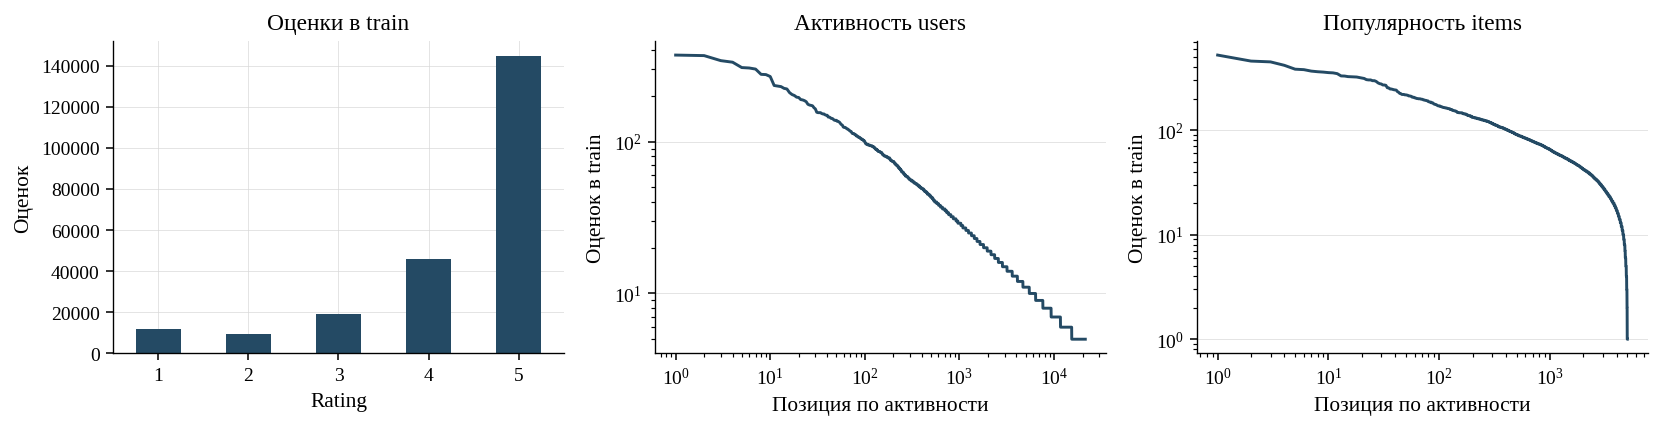

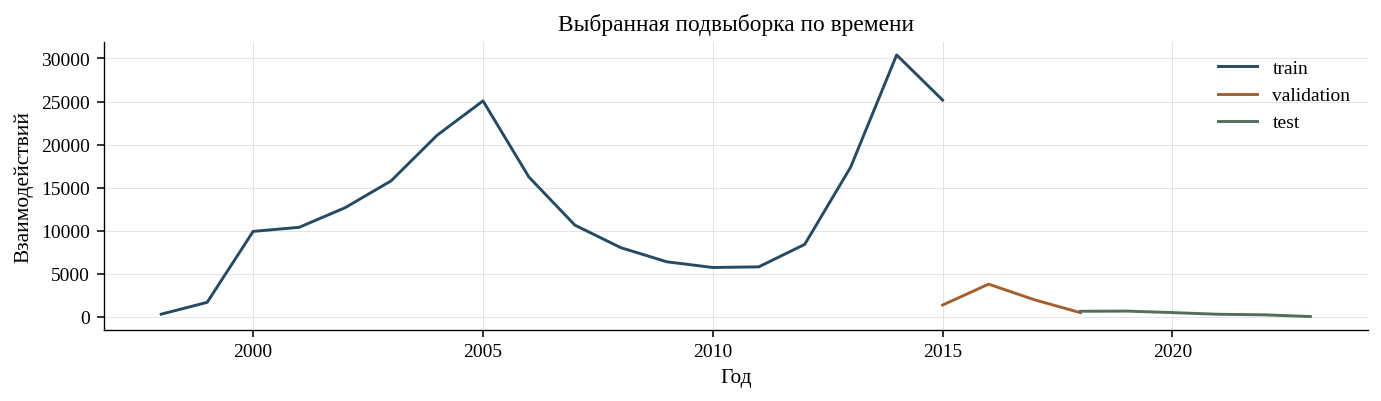

In [3]:
user_activity = train.groupby('user_idx').size()
item_activity = train.groupby('item_idx').size()
display(pd.DataFrame({'оценки на user': user_activity.describe(),
                      'оценки на item': item_activity.describe()}).round(2))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
train.rating.astype(int).value_counts().sort_index().plot.bar(ax=axes[0], color='#244a64', rot=0)
axes[0].set(xlabel='Rating', ylabel='Оценок', title='Оценки в train')
for axis, activity, title in [(axes[1], user_activity, 'Активность users'),
                               (axes[2], item_activity, 'Популярность items')]:
    axis.plot(np.arange(1, len(activity)+1), np.sort(activity)[::-1])
    axis.set(xscale='log', yscale='log', xlabel='Позиция по активности',
             ylabel='Оценок в train', title=title)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 3))
for name, frame in parts.items():
    years = pd.to_datetime(frame.timestamp, unit='ms', utc=True).dt.year
    years.value_counts().sort_index().plot(ax=ax, label=name)
ax.set(xlabel='Год', ylabel='Взаимодействий', title='Выбранная подвыборка по времени')
ax.legend()
plt.tight_layout()
plt.show()

В train преобладали высокие оценки. У половины пользователей не больше семи взаимодействий, у половины товаров - не больше 35 оценок. Порог в пять оценок я выбрала, чтобы у пользователя была история для коллаборативных методов.

In [4]:
metadata_report = pd.Series({
    'items': len(metadata),
    'есть в архиве': int(metadata.in_archive.sum()),
    'без архивной записи': int((~metadata.in_archive).sum()),
    'с названием': int(metadata.title.ne('').sum()),
    'без названия': int(metadata.title.eq('').sum()),
    'с жанрами': int(metadata.categories.map(bool).sum()),
    'медиана слов непустого названия': metadata.loc[metadata.title.ne(''), 'title'].str.split().str.len().median(),
    'уникальных жанров': metadata.categories.explode().nunique(),
}, name='значение')
display(metadata_report.to_frame())
display(metadata.categories.explode().value_counts().head(8).rename('items').to_frame())
features, feature_report = item_features(metadata)
features_ids, _ = item_features(metadata, use_metadata=False)
display(pd.Series(feature_report, name='признаков').to_frame())
print('Матрица item-признаков:', features.shape, '| ненулевых:', features.nnz)

,значение
items,4987.0
есть в архиве,3924.0
без архивной записи,1063.0
с названием,2468.0
без названия,2519.0
с жанрами,3866.0
медиана слов непустого названия,3.0
уникальных жанров,19.0


,items
categories,
Pop,3637
Rock,2411
Alternative Rock,835
Metal,644
R&B,521
Country,430
Folk,374
Soundtracks,290


,признаков
id,4987
categories,19
words,249


Матрица item-признаков: (4987, 5255) | ненулевых: 20084


Каталог я ограничила по памяти EASE: одна плотная матрица float64 для этих товаров занимает около 190 MiB.

Названия и жанры сопоставила по parent_asin и asin из архива 2014 года. Файл архива датирован 24.09.2015 по HTTP Last-Modified, до начала validation 05.10.2015; это условие проверила и в коде. Один архив использовала для validation и test. Если записи, названия или жанра не было, соответствующий блок признаков оставила нулевым. ID товара сохранила.

## 2. Протокол и метрики

Для validation я использовала историю из train. После подбора параметров переобучила модели на train + validation и сравнила их на test. Каталог, user/item mappings и преобразование признаков зафиксировала по исходному train. Из выдачи исключила все ранее оценённые товары, включая низкие оценки. Новых пользователей и товары в основное сравнение не включала.

Кандидаты - весь выбранный каталог минус история пользователя. При равных scores сортировала по ASIN. Метрики посчитала по пользователям хотя бы с одним будущим релевантным товаром из каталога.

До подбора я выбрала основную метрику NDCG@10 и вторую метрику Recall@10. При бинарной релевантности:

$$Recall@10(u)=\frac{\sum_{j=1}^{10}rel_{uj}}{|R_u|},\qquad
NDCG@10(u)=\frac{\sum_{j=1}^{10}rel_{uj}/\log_2(j+1)}
{\sum_{j=1}^{\min(10,|R_u|)}1/\log_2(j+1)}.$$

Recall показывает долю найденных релевантных товаров, NDCG дополнительно учитывает порядок. Усреднение - по пользователям, одинаковым для всех моделей.

In [5]:
validation = Evaluation(train, valid, SHAPE, k=K)
display(coverage_report.set_index('split').round(4))
print('Validation users:', len(validation.users))
print('Релевантных товаров на validation-user:',
      pd.Series(validation.relevance.getnnz(axis=1)[validation.users]).describe().round(2).to_dict())
print('Кандидатов на validation-user:',
      pd.Series(SHAPE[1]-validation.seen.getnnz(axis=1)[validation.users]).describe().round(2).to_dict())

,all_positive_pairs,positive_pairs_selected_users,positive_pairs_in_catalog,eval_users,user_coverage,catalog_coverage_selected_users
split,,,,,,
validation,860485,46111,7089,2459,0.0059,0.1537
test,829905,25208,2269,993,0.0024,0.0900


Validation users: 2459
Релевантных товаров на validation-user: {'count': 2459.0, 'mean': 2.88, 'std': 3.75, 'min': 1.0, '25%': 1.0, '50%': 2.0, '75%': 3.0, 'max': 45.0}
Кандидатов на validation-user: {'count': 2459.0, 'mean': 4974.46, 'std': 19.96, 'min': 4646.0, '25%': 4975.0, '50%': 4979.0, '75%': 4981.0, 'max': 4982.0}


## 3. Модели

**Item-CF.** Для наблюдаемой оценки $x_{ui}=r_{ui}-\bar r_u$. Сходство колонок - cosine на центрированных векторах, умноженный на $n_{ij}/(n_{ij}+\lambda_s)$, где $n_{ij}$ - число общих пользователей. Я оставила положительные top-L соседей и минимум три общие оценки.

$$\hat r_{ui}=\bar r_u+
\frac{\sum_{j\in N_L(i)\cap I_u}s_{ji}(r_{uj}-\bar r_u)}
{\sum_{j\in N_L(i)\cap I_u}|s_{ji}|}.$$

Если соседей не было, использовала среднюю оценку пользователя.

**ALS.** Я минимизировала ошибку только по наблюдаемым оценкам:
$$\sum_{(u,i)\in\Omega}(r_{ui}-p_u^\top q_i)^2+
\lambda(\|P\|_F^2+\|Q\|_F^2).$$
Я по очереди обновляла факторы users и items через ridge-решения в np.linalg.solve. Неизвестные оценки не заменяла нулями.

**EASE.** $X_{ui}=1$ для rating ≥ 4. Я решила задачу
$\|X-XB\|_F^2+\lambda\|B\|_F^2$ при $B_{ii}=0$.
Для $G=X^\top X+\lambda I$ и $P=G^{-1}$ получила $B_{ij}=-P_{ij}/P_{jj}$, $B_{jj}=0$. Решение получила через Cholesky solve, товары ранжировала по значениям строки $X_uB$.

**FM.** Я использовала user ID, item ID, музыкальные жанры и TF-IDF слов названия. Словарь - до 1000 слов, встречающихся минимум у пяти товаров train-каталога. TF-IDF нормирован внутри названия; категории имеют веса $1/\sqrt{n_{categories}}$.

$$f(x)=w^\top x+\frac12\sum_f\left[
\left(\sum_jv_{jf}x_j\right)^2-\sum_jv_{jf}^2x_j^2\right].$$

Я обучила FM на парах positive/negative с loss $\log(1+\exp(-(f(u,i^+)-f(u,i^-))))$ и L2. Positive - наблюдаемая оценка ≥ 4; negative равномерно выбирала из train-каталога вне всей train-истории пользователя. Для обучения использовала Adam. Для контроля обучила FM только с IDs.

**Пятая модель - ALS с собственным таргетом.** В таргете я объединила оценку и давность события. Низкую оценку считала отрицательным предпочтением, давний сигнал ослабила:
$$z_{ui}=\frac{r_{ui}-3}{2}\;2^{-(T-t_{ui})/(86400000\,h)},$$
где $T$ - начало прогнозируемого периода в миллисекундах, $h$ - период полураспада в днях. Оценки 1 и 5 дают предпочтения -1 и +1, оценка 3 - нейтральный ноль. Давние сигналы приближаются к нулю.

В функции потерь ALS я заменила исходную оценку $r_{ui}$ на $z_{ui}$. Confidence оставила единичным. Нулевые $z$ я сохранила как наблюдения. Для validation взяла $T$ на границе train, для test - на границе train + validation. Timestamp и rating прогнозируемого события в таргет не включала.

## 4. Проверки реализации

In [6]:
# Небольшие примеры проверяют формулы до обучения на основных данных.
toy = pd.DataFrame({
    'user_idx': [0,0,0,1,1,1,2,2,2],
    'item_idx': [0,1,2,0,1,2,0,1,2],
    'rating': [5.,3.,1.,4.,3.,2.,5.,2.,2.],
    'timestamp': np.arange(9)*86_400_000,
})
toy_shape = (3, 3)
knn_check = ItemKNN(neighbors=2, min_common=2).fit(toy, toy_shape)
assert np.all(knn_check.similarity.diagonal() == 0)
assert (knn_check.similarity.data > 0).all()
assert np.isclose(knn_check.similarity[1,2], (3/13)/np.sqrt(6))
assert np.isclose(knn_check.score(np.array([2]))[0,1], 2.)
assert np.isfinite(knn_check.score(np.arange(3))).all()

als_check = ALS(factors=2, regularization=.1, iterations=8).fit(toy, toy_shape)
assert (np.diff(als_check.losses) <= 1e-7).all()
zeros = ALS(factors=2, regularization=.1, iterations=3).fit(
    toy, toy_shape, target=np.zeros(len(toy)))
assert np.allclose(zeros.score(np.arange(3)), 0)

ease_check = EASE(regularization=3).fit(toy, toy_shape)
x = matrix(toy, toy_shape, positive_only=True).toarray()
g = x.T@x + 3*np.eye(3)
gradient = g@ease_check.weights - x.T@x
assert np.allclose(gradient[~np.eye(3, dtype=bool)], 0, atol=1e-10)
assert np.all(ease_check.weights.diagonal() == 0)

f = sparse.csr_matrix([[1.,0.,.5], [0.,1.,1.], [1.,0.,0.]])
fm_check = FactorizationMachine(factors=3, regularization=.02).initialize(3, f)
xp = fm_check.pairs([0,1], [0,1])
xn = fm_check.pairs([0,1], [2,2])
fast, _, _ = fm_check.forward(xp)
brute = []
for row in xp:
    ids, vals = row.indices, row.data
    result = float(np.asarray(row@fm_check.w).item())
    for a in range(len(ids)):
        for b in range(a+1, len(ids)):
            result += vals[a]*vals[b]*(fm_check.v[ids[a]]@fm_check.v[ids[b]])
    brute.append(result)
assert np.allclose(fast, brute)
_, gw, gv = fm_check.loss_grad(xp, xn)
for parameter, gradient, index in [(fm_check.w, gw, 0),
                                    (fm_check.w, gw, 3),
                                    (fm_check.v, gv, (0,1)),
                                    (fm_check.v, gv, (3,2))]:
    old = parameter[index]
    epsilon = 1e-6
    parameter[index] = old + epsilon
    plus = fm_check.loss_grad(xp, xn)[0]
    parameter[index] = old - epsilon
    minus = fm_check.loss_grad(xp, xn)[0]
    parameter[index] = old
    assert np.isclose((plus-minus)/(2*epsilon), gradient[index], atol=1e-7)
fm_check._prepare_scores()
assert np.allclose(fast, fm_check.score(np.array([0,1]))[[0,1],[0,1]])

rmodel = RecencyALS(half_life_days=1.)
probe = pd.DataFrame({'rating':[5.,5.,3.,1.], 'timestamp':[0,86_400_000,86_400_000,86_400_000]})
assert np.allclose(rmodel.target(probe, 86_400_000), [.5,1.,0.,-1.])

history_check = pd.DataFrame({'user_idx':[0], 'item_idx':[0], 'rating':[5.]})
target_check = pd.DataFrame({'user_idx':[0,0], 'item_idx':[1,2], 'rating':[4.,5.]})
evaluation_check = Evaluation(history_check, target_check, (1,12), k=10)
class Fixed:
    def score(self, users):
        return np.array([[100,12,10,11,9,8,7,6,5,4,3,2.]]*len(users))
values, _ = evaluation_check.evaluate(Fixed())
expected_ndcg = (1 + 1/np.log2(4))/(1 + 1/np.log2(3))
assert np.isclose(values['Recall@10'], 1)
assert np.isclose(values['NDCG@10'], expected_ndcg)
print('Проверены ALS, наблюдаемые нулевые targets, EASE, FM score/градиенты, таргет и метрики.')

Проверены ALS, наблюдаемые нулевые targets, EASE, FM score/градиенты, таргет и метрики.


## 5. Подбор на validation

Параметры я выбрала по NDCG@10; при равенстве - первый вариант в зафиксированном порядке. Iterations ALS - 12. Для FM перебрала learning_rate ∈ {0.003, 0.01}, regularization ∈ {1e-5, 1e-4} и эпохи ∈ {5, 10, 20}. Factors=16, batch_size=2048.

In [7]:
spaces = {
    'Item-CF': [dict(neighbors=n, shrinkage=s, min_common=3)
                for n,s in product([50,100], [10.,50.])],
    'ALS': [dict(factors=f, regularization=r, iterations=12, seed=SEED)
            for f,r in product([16,32], [1.,10.])],
    'EASE': [dict(regularization=r) for r in [10.,100.,500.]],
    'Recency ALS': [dict(factors=f, regularization=r, half_life_days=h,
                        iterations=12, seed=SEED)
                    for f,r,h in product([16,32], [.1,1.], [365.,1095.])],
}
constructors = {'Item-CF':ItemKNN, 'ALS':ALS, 'EASE':EASE, 'Recency ALS':RecencyALS}
display(pd.DataFrame([
    {'model':name, 'вариантов':len(space),
     'поиск':{key:sorted({p[key] for p in space}) for key in space[0]
              if len({p[key] for p in space}) > 1}}
    for name,space in spaces.items()
]))
FM_CHECKPOINTS = [5,10,20]
selected = {}
validation_rows = []

,model,вариантов,поиск
0,Item-CF,4,"{'neighbors': [50, 100], 'shrinkage': [10.0, 50.0]}"
1,ALS,4,"{'factors': [16, 32], 'regularization': [1.0, 10.0]}"
2,EASE,3,"{'regularization': [10.0, 100.0, 500.0]}"
3,Recency ALS,8,"{'factors': [16, 32], 'regularization': [0.1, 1.0], 'half_life_days': [365.0, 1095.0]}"


In [8]:
def fit_model(name, parameters, history, cutoff):
    model = constructors[name](**parameters)
    start = perf_counter()
    if name == 'Recency ALS':
        model.fit(history, SHAPE, cutoff=cutoff)
    else:
        model.fit(history, SHAPE)
    return model, perf_counter()-start

for name, space in spaces.items():
    print('Подбор:', name, flush=True)
    best_ndcg = -np.inf
    for parameters in space:
        model, elapsed = fit_model(name, parameters, train, TRAIN_CUTOFF)
        metrics, _ = validation.evaluate(model)
        validation_rows.append({'model':name, 'parameters':parameters.copy(),
                                'fit_seconds':elapsed, **metrics})
        if metrics['NDCG@10'] > best_ndcg:
            best_ndcg = metrics['NDCG@10']
            selected[name] = parameters.copy()
        del model
        gc.collect()
validation_table = pd.DataFrame(validation_rows)
display(validation_table[['model','parameters','NDCG@10','Recall@10','fit_seconds']].round(5))

Подбор: Item-CF


Подбор: ALS


Подбор: EASE


Подбор: Recency ALS


,model,parameters,NDCG@10,Recall@10,fit_seconds
0,Item-CF,"{'neighbors': 50, 'shrinkage': 10.0, 'min_common': 3}",0.00464,0.00894,0.82207
1,Item-CF,"{'neighbors': 50, 'shrinkage': 50.0, 'min_common': 3}",0.00462,0.00887,0.82576
2,Item-CF,"{'neighbors': 100, 'shrinkage': 10.0, 'min_common': 3}",0.00325,0.00617,0.91508
3,Item-CF,"{'neighbors': 100, 'shrinkage': 50.0, 'min_common': 3}",0.00316,0.00605,0.88137
4,ALS,"{'factors': 16, 'regularization': 1.0, 'iterations': 12, 'seed': 42}",0.00208,0.00406,7.24451
5,ALS,"{'factors': 16, 'regularization': 10.0, 'iterations': 12, 'seed': 42}",0.00947,0.01399,7.19105
6,ALS,"{'factors': 32, 'regularization': 1.0, 'iterations': 12, 'seed': 42}",0.00459,0.00887,10.19043
7,ALS,"{'factors': 32, 'regularization': 10.0, 'iterations': 12, 'seed': 42}",0.01032,0.01408,10.13688
8,EASE,{'regularization': 10.0},0.03668,0.05607,7.37810
9,EASE,{'regularization': 100.0},0.03608,0.05763,7.02170


In [9]:
fm_validation = {}
fm_search_rows = []
best_fm_ndcg = -np.inf
for lr, reg in product([.003,.01], [1e-5,1e-4]):
    parameters = dict(factors=16, learning_rate=lr, regularization=reg,
                      batch_size=2048, seed=SEED)
    print('FM + metadata:', parameters, flush=True)
    model = FactorizationMachine(**parameters, epochs=max(FM_CHECKPOINTS))
    model.fit(train, SHAPE, features, evaluator=validation, checkpoints=FM_CHECKPOINTS)
    trace = pd.DataFrame(model.trace)
    measured = trace.dropna(subset=['NDCG@10'])
    for _, row in measured.iterrows():
        fm_search_rows.append({'learning_rate':lr, 'regularization':reg, **row.to_dict()})
    score = measured['NDCG@10'].max()
    if score > best_fm_ndcg:
        best_fm_ndcg = score
        selected['FM + metadata'] = {**parameters, 'epochs':model.best_epoch}
        fm_validation['FM + metadata'] = trace.copy()
    del model
    gc.collect()

# Контроль использует те же настройки; по нему FM + metadata не подбирается.
selected['FM IDs'] = selected['FM + metadata'].copy()
control_parameters = {**selected['FM IDs'], 'epochs':max(FM_CHECKPOINTS)}
control = FactorizationMachine(**control_parameters).fit(
    train, SHAPE, features_ids, evaluator=validation, checkpoints=FM_CHECKPOINTS)
fm_validation['FM IDs'] = pd.DataFrame(control.trace)
del control
gc.collect()
display(pd.DataFrame(fm_search_rows)[
    ['learning_rate','regularization','epoch','BPR_loss','NDCG@10','Recall@10']].round(6))
control_row = fm_validation['FM IDs'][
    fm_validation['FM IDs'].epoch == selected['FM IDs']['epochs']]
display(control_row[['epoch','BPR_loss','NDCG@10','Recall@10']].assign(model='FM IDs').round(6))

FM + metadata: {'factors': 16, 'learning_rate': 0.003, 'regularization': 1e-05, 'batch_size': 2048, 'seed': 42}


FM epoch 5: loss=0.4481, validation NDCG@10=0.00470


FM epoch 10: loss=0.3613, validation NDCG@10=0.00863


FM epoch 20: loss=0.3144, validation NDCG@10=0.01213


FM + metadata: {'factors': 16, 'learning_rate': 0.003, 'regularization': 0.0001, 'batch_size': 2048, 'seed': 42}


...

FM epoch 5: loss=0.5036, validation NDCG@10=0.01351


FM epoch 10: loss=0.4224, validation NDCG@10=0.01671


FM epoch 20: loss=0.4026, validation NDCG@10=0.01834


,learning_rate,regularization,epoch,BPR_loss,NDCG@10,Recall@10
0,0.003,0.00001,5.0,0.448055,0.004703,0.006393
1,0.003,0.00001,10.0,0.361278,0.008628,0.011903
2,0.003,0.00001,20.0,0.314432,0.012128,0.017436
3,0.003,0.00010,5.0,0.573826,0.001599,0.002736
4,0.003,0.00010,10.0,0.550900,0.003129,0.004758
5,0.003,0.00010,20.0,0.529423,0.004488,0.005965
6,0.010,0.00001,5.0,0.381633,0.010182,0.015273
7,0.010,0.00001,10.0,0.348378,0.011077,0.017175
8,0.010,0.00001,20.0,0.334904,0.011502,0.018253
9,0.010,0.00010,5.0,0.596504,0.002698,0.004969


,epoch,BPR_loss,NDCG@10,Recall@10,model
19,20,0.402625,0.018344,0.026252,FM IDs


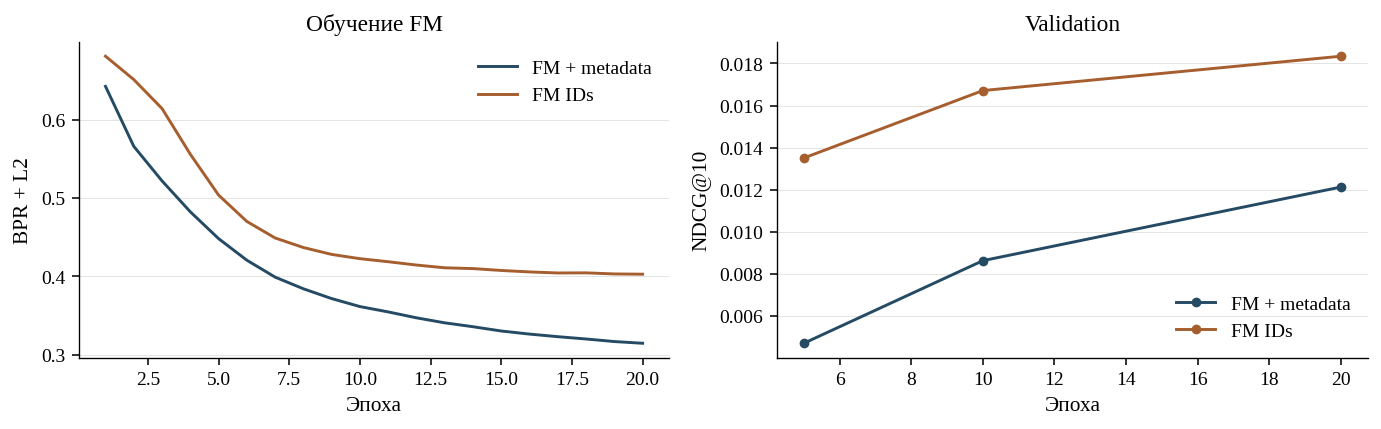

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for name, trace in fm_validation.items():
    axes[0].plot(trace.epoch, trace.BPR_loss, label=name)
    measured = trace.dropna(subset=['NDCG@10'])
    axes[1].plot(measured.epoch, measured['NDCG@10'], marker='o', label=name)
axes[0].set(xlabel='Эпоха', ylabel='BPR + L2', title='Обучение FM')
axes[1].set(xlabel='Эпоха', ylabel='NDCG@10', title='Validation')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

## 6. Финальное обучение и test

С выбранными параметрами я переобучила модели на train + validation, сохранив каталог и признаки. FM IDs обучила с теми же параметрами и числом эпох, что FM + metadata, чтобы проверить влияние метаданных. По test настройки не меняла.

In [11]:
final_history = pd.concat([train, valid], ignore_index=True)
test_evaluation = Evaluation(final_history, test, SHAPE, k=K)
assert np.array_equal(np.unique(final_history.user_idx), np.arange(SHAPE[0]))
final_models = {}
fit_times = {}
for name in ['Item-CF','ALS','EASE','Recency ALS']:
    print('Final fit:', name, flush=True)
    final_models[name], fit_times[name] = fit_model(
        name, selected[name], final_history, TEST_CUTOFF)
for name, transform in [('FM + metadata',features), ('FM IDs',features_ids)]:
    print('Final fit:', name, flush=True)
    start = perf_counter()
    final_models[name] = FactorizationMachine(**selected[name]).fit(final_history, SHAPE, transform)
    fit_times[name] = perf_counter()-start
print('Переобучение завершено.')

Final fit: Item-CF


Final fit: ALS


Final fit: EASE


Final fit: Recency ALS


Final fit: FM + metadata


Final fit: FM IDs


Переобучение завершено.


In [12]:
test_rows, test_details = [], {}
ordered_models = ['Item-CF','ALS','EASE','FM + metadata','Recency ALS','FM IDs']
for name in ordered_models:
    metrics, details = test_evaluation.evaluate(final_models[name])
    test_rows.append({'model':name, **metrics, 'fit_seconds':fit_times[name],
                      'users':len(details)})
    test_details[name] = details
comparison = pd.DataFrame(test_rows).set_index('model')
assert comparison.users.nunique() == 1
for name in ordered_models:
    assert test_details[name].user_idx.equals(test_details['ALS'].user_idx)
table = comparison[['NDCG@10','Recall@10','fit_seconds']].copy()
table['выбранные параметры'] = [
    {key:value for key,value in selected[name].items()
     if key in {'factors','regularization','neighbors','shrinkage','half_life_days','epochs','learning_rate'}}
    for name in table.index
]
with pd.option_context('display.max_colwidth', None):
    display(table.round(5))
print('Test eligible users:', len(test_evaluation.users))
print('Test relevant pairs:', test_evaluation.relevance.nnz)
print('Релевантных товаров на user:',
      pd.Series(test_evaluation.relevance.getnnz(axis=1)[test_evaluation.users]).describe().round(2).to_dict())
print('Время зависит от компьютера. Fit time не включает подбор параметров.')

,NDCG@10,Recall@10,fit_seconds,выбранные параметры
model,,,,
Item-CF,0.00538,0.01171,0.82135,"{'neighbors': 50, 'shrinkage': 10.0}"
ALS,0.00501,0.00840,9.46331,"{'factors': 32, 'regularization': 10.0}"
EASE,0.02835,0.04358,6.54300,{'regularization': 10.0}
FM + metadata,0.00522,0.01028,30.63785,"{'factors': 16, 'learning_rate': 0.003, 'regularization': 1e-05, 'epochs': 20}"
Recency ALS,0.01250,0.01836,8.70893,"{'factors': 32, 'regularization': 1.0, 'half_life_days': 365.0}"
FM IDs,0.01423,0.02072,29.17091,"{'factors': 16, 'learning_rate': 0.003, 'regularization': 1e-05, 'epochs': 20}"


Test eligible users: 993
Test relevant pairs: 2269
Релевантных товаров на user: {'count': 993.0, 'mean': 2.28, 'std': 2.93, 'min': 1.0, '25%': 1.0, '50%': 1.0, '75%': 2.0, 'max': 36.0}
Время зависит от компьютера. Fit time не включает подбор параметров.


## 7. Выводы

На test лучший результат я получила для EASE: NDCG@10=0.02835, Recall@10=0.04358. Regularization=10 выбрала по основной метрике на validation.

У исходного ALS NDCG@10=0.00501 и Recall@10=0.00840. С собственным таргетом я получила NDCG@10=0.01250 и Recall@10=0.01836. По validation выбрала 32 фактора, regularization=1 и half_life=365 дней.

Для FM с метаданными я получила NDCG@10=0.00522, для FM IDs - 0.01423. Обе модели я обучила 20 эпох с factors=16, learning_rate=0.003 и regularization=1e-5. Добавление этих признаков качество не улучшило.

Ограничения эксперимента:

- Оценка относится к 993 test-пользователям с 2 269 релевантными парами. Каталог покрыл около 9% будущих положительных оценок отобранных пользователей.
- Для 1 063 товаров отсутствовала архивная запись, для 2 519 - название.
- В данных наблюдались только оставленные оценки.
- Я проверила один временной split и один seed.
- Собственный таргет одновременно изменил шкалу оценок и учёт давности событий.

In [13]:
# Итоговая проверка состояния ноутбука и общих правил.
assert set(['Item-CF','ALS','EASE','FM + metadata','Recency ALS']) <= set(final_models)
assert 100_000 <= sum(map(len, parts.values())) <= 2_000_000
assert min(SHAPE) >= 1000
assert np.isfinite(comparison[['NDCG@10','Recall@10']].to_numpy()).all()
assert comparison[['NDCG@10','Recall@10']].ge(0).all().all()
assert comparison[['NDCG@10','Recall@10']].le(1).all().all()
assert test_evaluation.seen.multiply(test_evaluation.relevance).nnz == 0
assert np.allclose(final_models['EASE'].weights.diagonal(), 0)
assert all((np.diff(final_models[name].losses) <= 1e-6).all()
           for name in ['ALS','Recency ALS'])
print('Пять моделей, общий протокол и итоговые результаты проверены.')

Пять моделей, общий протокол и итоговые результаты проверены.
